# N163 · Predict delayed incoming loss from one learning-rate choice

Use the two N161 development streams, the warm RGB64 MAE, fixed current-image
training, and the completed quarter and full rate references. Each new arm sees
15,232 ordered images in each pool. No RankMe guard in this pilot.

At an eligible arrival choose skip, quarter or nominal. Score the **following
16 arrivals** by mean reconstruction loss measured before each image's update.
Intervening updates use quarter rate. The next decision follows the last
measurement, so feedback windows do not overlap. Images enter the features and
learner in arrival order. The lagged context reaches back at most 128 images.

Offline, fork the learner and optimizer from the same state, vary the one rate,
then use common quarter-rate continuation. Fit on separate archived clips,
calibrate action scores on another split, and report a held-out test. A subset
measures 96-arrival outcomes under the common continuation. The oracle uses
measured outcomes and is a headroom diagnostic.

Online, every 12 decision slots allocate three skips, eight quarter rates, and
one nominal rate. This gives both new arms equal optimizer steps and LR dose.
Total LR dose also equals always-quarter. The matched randomized arm uniformly
permutes those rates without seeing the images. The predictor learns the observed
loss after the window matures. A 12.5% randomized exploration chance among
available rates supplies evidence for rate-specific online adjustments.

Report pre-update loss, actual training loss, contextual RankMe, a fixed
day/night audit, and forecast RMSE versus persistence. The delayed forecast is
separate from the simple H1 next-arrival loss, RankMe and variance forecasts.
These are development streams. The two full-length arms are a bounded pilot.


## Live status

**complete** · Both delayed-loss and matched-random arms finished on both pools

Updated UTC `2026-11-07T00:45:51+00:00` · PID `49500`.

All 60,928 new arrivals are complete.

Free disk **16.3 GiB** with a 3 GiB reserve.

## Held-out paired results

39 origins, 36 in complete quota groups.
Positive gain means lower loss than always-quarter.

| Selector | H16 loss gain |
|---|---:|
| Frozen MPC | -0.000133 |
| Expected matched random | -0.000143 |
| Matched hindsight oracle | +0.000916 |

| Rate | H16 forecast RMSE | Persistence RMSE | Advantage RMSE | Zero-advantage RMSE |
|---|---:|---:|---:|---:|
| Skip | 0.078407 | 0.130404 | 0.001724 | 0.002025 |
| Quarter | 0.078980 | 0.130412 | — | — |
| Nominal | 0.080663 | 0.132042 | 0.003522 | 0.003706 |

Frozen selector H96 gain **-0.000112** over 6 preselected origins.

## Actual outcomes

| Pool / arm | Images | Incoming loss | RankMe | Training loss | Skip / quarter / full | Audit loss | Audit RankMe |
|---|---:|---:|---:|---:|---:|---:|---:|
| pool_1/quarter_admission | 15,232 | 0.79488 | 1.5179 | 0.77578 | 0 / 15,232 / 0 | 1.05340 | 2.7629 |
| pool_1/full_admission | 15,232 | 0.78534 | 1.1910 | 0.77030 | 0 / 0 / 15,232 | 1.27905 | 2.0722 |
| pool_2/quarter_admission | 15,232 | 0.83104 | 1.5730 | 0.81085 | 0 / 15,232 / 0 | 1.02391 | 2.3438 |
| pool_2/full_admission | 15,232 | 0.82131 | 1.2777 | 0.80445 | 0 / 0 / 15,232 | 1.16899 | 1.9023 |
| pool_1/delayed_mpc | 15,232 | 0.79530 | 1.5347 | 0.77640 | 237 / 14,916 / 79 | 1.04014 | 3.0848 |
| pool_1/matched_random | 15,232 | 0.79574 | 1.5016 | 0.77674 | 237 / 14,916 / 79 | 1.04426 | 2.8304 |
| pool_2/delayed_mpc | 15,232 | 0.83120 | 1.5781 | 0.81115 | 237 / 14,916 / 79 | 1.02406 | 2.2597 |
| pool_2/matched_random | 15,232 | 0.83058 | 1.5814 | 0.81047 | 237 / 14,916 / 79 | 1.00866 | 2.2501 |

## Forecast RMSE against persistence

| Pool / arm | Delayed labels | H16 loss | H1 next loss | H1 next RankMe | H1 next variance |
|---|---:|---:|---:|---:|---:|
| pool_1/quarter_admission | 0 | — | 0.03545 / 0.03570 | 0.04289 / 0.04291 | 0.01292 / 0.01293 |
| pool_1/full_admission | 0 | — | 0.04297 / 0.04334 | 0.02257 / 0.02254 | 0.00964 / 0.00963 |
| pool_2/quarter_admission | 0 | — | 0.03497 / 0.03524 | 0.04424 / 0.04429 | 0.01536 / 0.01537 |
| pool_2/full_admission | 0 | — | 0.03969 / 0.04006 | 0.03167 / 0.03169 | 0.01081 / 0.01081 |
| pool_1/delayed_mpc | 948 | 0.04234 / 0.07287 | 0.03500 / 0.03524 | 0.04437 / 0.04439 | 0.01294 / 0.01295 |
| pool_1/matched_random | 948 | 0.06183 / 0.07362 | 0.03546 / 0.03571 | 0.04179 / 0.04181 | 0.01292 / 0.01292 |
| pool_2/delayed_mpc | 948 | 0.04974 / 0.07896 | 0.03488 / 0.03515 | 0.04475 / 0.04480 | 0.01540 / 0.01541 |
| pool_2/matched_random | 948 | 0.06483 / 0.07901 | 0.03485 / 0.03513 | 0.04503 / 0.04508 | 0.01533 / 0.01534 |

## Complete comparison

Positive incoming gain favors delayed MPC.

| Pool | vs quarter | vs matched random | RankMe difference vs matched random |
|---|---:|---:|---:|
| pool_1 | -0.000421 | +0.000434 | +0.03307 |
| pool_2 | -0.000161 | -0.000622 | -0.00330 |

### Actual loss and RankMe

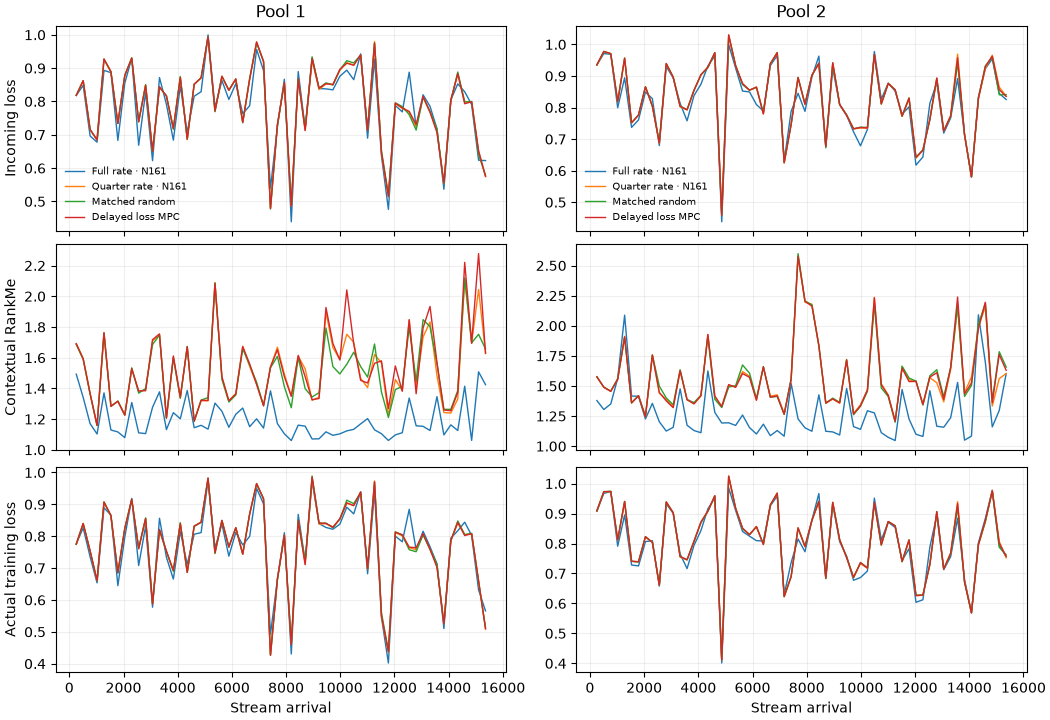

### Forecast RMSE

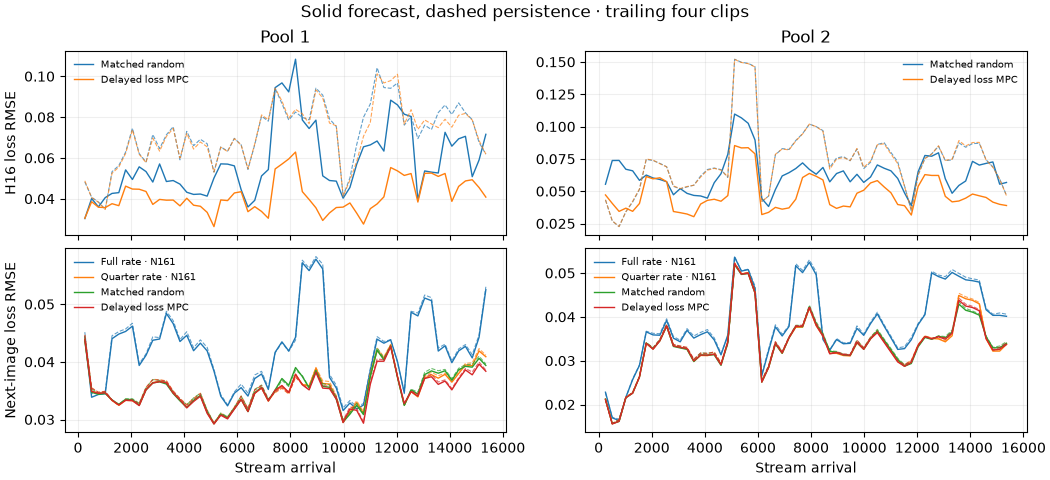